In [1]:
import sqlite3
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Connect to the database located in the data/ folder
conn = sqlite3.connect('../data/rental_analyzer.db')

# Write a SQL query and load the results directly into a Pandas DataFrame
query = "SELECT * FROM properties"
df = pd.read_sql_query(query, conn)

# Close the connection
conn.close()

# Display the first 5 rows
df.head()

,property_id,neighborhood,bhk_size,sqft,furnishing,rent_monthly,maintenance_monthly,distance_to_transit_km
0,501,Hinjewadi,3,1409,Fully Furnished,43940,4368,1.4
1,502,Baner,3,1414,Semi-Furnished,42480,4311,4.0
2,503,Baner,3,1762,Semi-Furnished,37325,4992,4.8
3,504,Hinjewadi,3,1807,Unfurnished,37931,3305,0.8
4,505,Viman Nagar,2,1194,Fully Furnished,28800,3100,2.7


In [2]:
# Check for missing values and understand data types
print(df.info())

# Get statistical summaries (mean, min, max for rent, sqft, etc.)
display(df.describe())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 8 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   property_id             500 non-null    int64  
 1   neighborhood            500 non-null    object 
 2   bhk_size                500 non-null    int64  
 3   sqft                    500 non-null    int64  
 4   furnishing              500 non-null    object 
 5   rent_monthly            500 non-null    int64  
 6   maintenance_monthly     500 non-null    int64  
 7   distance_to_transit_km  500 non-null    float64
dtypes: float64(1), int64(5), object(2)
memory usage: 31.4+ KB
None


,property_id,bhk_size,sqft,rent_monthly,maintenance_monthly,distance_to_transit_km
count,500.000000,500.000000,500.000000,500.000000,500.000000,500.000000
mean,750.500000,1.948000,1079.556000,27055.586000,3238.460000,2.539600
std,144.481833,0.818924,442.178741,10201.548232,1015.677554,1.387675
min,501.000000,1.000000,421.000000,10043.000000,1500.000000,0.200000
25%,625.750000,1.000000,639.750000,17441.000000,2341.500000,1.400000
50%,750.500000,2.000000,1063.000000,26918.000000,3224.000000,2.500000
75%,875.250000,3.000000,1427.250000,36704.750000,4109.500000,3.700000
max,1000.000000,3.000000,1988.000000,45942.000000,5000.000000,5.000000


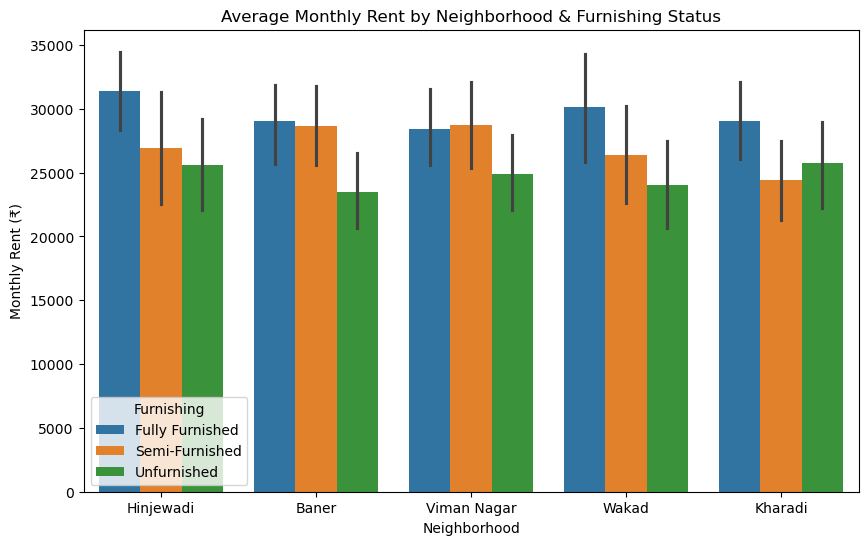

In [3]:
plt.figure(figsize=(10, 6))
sns.barplot(data=df, x='neighborhood', y='rent_monthly', hue='furnishing')

plt.title('Average Monthly Rent by Neighborhood & Furnishing Status')
plt.ylabel('Monthly Rent (₹)')
plt.xlabel('Neighborhood')
plt.legend(title='Furnishing')
plt.show()

In [4]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, r2_score
import joblib

# 1. PREPARE THE DATA (Feature Engineering)
# Drop the ID column as it doesn't predict price
df_ml = df.drop('property_id', axis=1)

# Convert 'furnishing' into ranked numbers (Ordinal Encoding)
furnishing_map = {'Unfurnished': 0, 'Semi-Furnished': 1, 'Fully Furnished': 2}
df_ml['furnishing_code'] = df_ml['furnishing'].map(furnishing_map)
df_ml = df_ml.drop('furnishing', axis=1)

# Convert 'neighborhood' into binary columns (One-Hot Encoding)
# e.g., creates columns like 'neighborhood_Wakad' with True/False
df_ml = pd.get_dummies(df_ml, columns=['neighborhood'], drop_first=True)

# 2. DEFINE FEATURES (X) AND TARGET (y)
X = df_ml.drop('rent_monthly', axis=1) # Everything except rent
y = df_ml['rent_monthly']              # Only rent

# 3. SPLIT THE DATA
# 80% of data to train the model, 20% to test its accuracy
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 4. TRAIN THE MODEL
print("Training the Random Forest model...")
model = RandomForestRegressor(n_estimators=100, random_state=42)
model.fit(X_train, y_train)

# 5. EVALUATE PERFORMANCE
predictions = model.predict(X_test)
mae = mean_absolute_error(y_test, predictions)
r2 = r2_score(y_test, predictions)

print("-" * 30)
print(f"Mean Absolute Error: ₹{mae:,.2f}")
print(f"Model Accuracy (R² Score): {r2:.2f}") 
# An R² score closer to 1.0 means the model learned the patterns well

# 6. SAVE THE MODEL
# We save this so we can use it in applications or scripts later
joblib.dump(model, '../models/rental_rf_model.pkl')
print("-" * 30)
print("Model saved to models/rental_rf_model.pkl!")

Training the Random Forest model...
------------------------------
Mean Absolute Error: ₹1,662.97
Model Accuracy (R² Score): 0.96
------------------------------
Model saved to models/rental_rf_model.pkl!


# **handles the preprocessing, training, evaluation, and saving the model**

In [5]:
import pandas as pd
import sqlite3
import joblib

# 1. Load the original raw data from SQLite
conn = sqlite3.connect('../data/rental_analyzer.db')
df = pd.read_sql_query("SELECT * FROM properties", conn)
conn.close()

# 2. Load the trained model
model = joblib.load('../models/rental_rf_model.pkl')

# 3. Preprocess the full dataset exactly as we did for training
df_ml = df.drop('property_id', axis=1)
furnishing_map = {'Unfurnished': 0, 'Semi-Furnished': 1, 'Fully Furnished': 2}
df_ml['furnishing_code'] = df_ml['furnishing'].map(furnishing_map)
df_ml = df_ml.drop('furnishing', axis=1)

# Ensure one-hot encoding matches the training data exactly
df_ml = pd.get_dummies(df_ml, columns=['neighborhood'], drop_first=True)
X_full = df_ml.drop('rent_monthly', axis=1)

# 4. Generate Predictions
df['predicted_rent'] = model.predict(X_full).round(0)

# Calculate the difference (Actual - Predicted)
# Negative value = Good Deal (Rent is lower than model predicts)
# Positive value = Overpriced (Rent is higher than model predicts)
df['price_difference'] = df['rent_monthly'] - df['predicted_rent']

# 5. Export to CSV for PowerBI
csv_path = '../data/powerbi_export.csv'
df.to_csv(csv_path, index=False)

print(f"Success! Exported {len(df)} records with ML predictions to {csv_path}")

Success! Exported 500 records with ML predictions to ../data/powerbi_export.csv


# **It will load your data, apply the model to predict the rent for every property, and calculate whether a property is "overpriced" or a "good deal" before saving it**